# Phytate PMF analysis

Loads the extracted per-condition data into a table-of-tables indexed by `(ionic_strength, pH)`.
Each cell (`pmf`, `potential_all`, `potential_peptide`, `shape`, `charge`) holds that quantity's own `[r, ...]` DataFrame on its native grid.

Regenerate the CSVs first if needed: `python plot_pmf.py` (writes `all_pmfs.csv`) and `python extract_data.py` (writes `charge.csv`, `polymer_shape.csv`, `potential.csv`).

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
KEY = ["ionic_strength", "pH"]


def _by_condition(df, cols):
    """(ionic_strength, pH) -> sub-frame of [r, *cols], sorted by r."""
    return {
        cond: g.sort_values("r")[["r", *cols]].reset_index(drop=True) for cond, g in df.groupby(KEY)
    }


def load(data_dir="."):
    """Merge the extracted CSVs into a table-of-tables indexed by (ionic_strength, pH).

    Columns pmf, potential_all, potential_peptide, shape, charge, rot_msd each hold
    that quantity's own [r, ...] DataFrame (or None where a condition is missing).
    """
    d = Path(data_dir)
    pmf = pd.read_csv(d / "all_pmfs.csv")
    charge = pd.read_csv(d / "charge.csv")
    shape = pd.read_csv(d / "polymer_shape.csv")
    pot = pd.read_csv(d / "potential.csv")
    msd = pd.read_csv(d / "rotational_msd.csv")

    # charge.csv is long (one row per selection) -> wide, one column per selection
    charge = (
        charge.pivot_table(index=KEY + ["r"], columns="selection", values="charge")
        .rename(columns={"molecule peptide": "charge_peptide", "atomtype INO": "charge_phytate"})
        .reset_index()
    )

    shape_cols = [c for c in shape.columns if c not in KEY + ["r"]]
    quantities = {
        "pmf": _by_condition(pmf, ["pmf_kT", "stderr_kT"]),
        "potential_all": _by_condition(pot, ["potential_all_mV"]),
        "potential_peptide": _by_condition(pot, ["potential_peptide_mV"]),
        "shape": _by_condition(shape, shape_cols),
        "charge": _by_condition(charge, ["charge_peptide", "charge_phytate"]),
        "rot_msd": _by_condition(msd, ["msd_rot"]),
    }
    conditions = sorted(set().union(*(q.keys() for q in quantities.values())))
    return pd.DataFrame(
        [
            {**dict(zip(KEY, cond)), **{name: q.get(cond) for name, q in quantities.items()}}
            for cond in conditions
        ]
    ).set_index(KEY)

In [3]:
data = load()
data.index.tolist()

[(0.005, 4.0),
 (0.005, 6.0),
 (0.005, 7.0),
 (0.005, 10.0),
 (0.03, 4.0),
 (0.03, 6.0),
 (0.03, 7.0),
 (0.03, 10.0),
 (0.15, 4.0),
 (0.15, 6.0),
 (0.15, 7.0),
 (0.15, 10.0),
 (1000.0, 4.0),
 (1000.0, 6.0),
 (1000.0, 7.0),
 (1000.0, 10.0)]

In [4]:
# Everything for one condition, each on its own r grid
# fig, ax = plt.subplots(figsize=(7, 4))

# def plot_charge(I, pH, ax):
#     row = data.loc[(I, pH)]
#     ax.plot(row["charge"].r, row["charge"].charge_phytate, label="phytate charge")
#     ax.set_xlabel("r = distance from decorated wall (\u00c5)")
#     ax.legend()
#     ax.set_title("I = 0.005 M, pH 7")

# plot_charge(I=0.005, pH=7.0, ax=ax)

## Potential of mean force or _free energy of interaction_

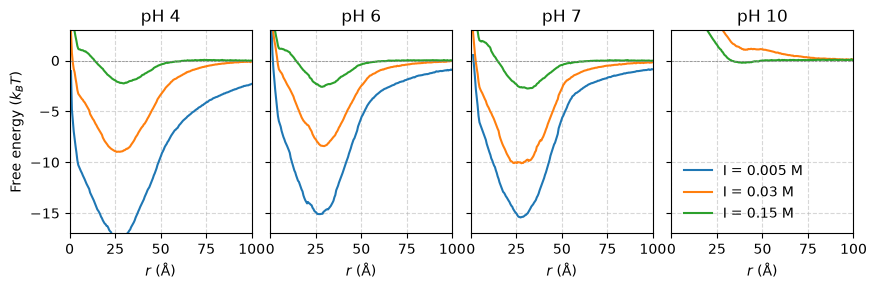

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)


def plot_pmf(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["pmf"] is None:
            continue
        pmf = row["pmf"]
        gofr = np.exp(-pmf.pmf_kT)
        # ax.fill_between(pmf.r, pmf.p8f_kT - pmf.stderr_kT, pmf.pmf_kT + pmf.stderr_kT, alpha=0.2)
        ax.plot(pmf.r, pmf.pmf_kT, label=f"I = {ionic:g} M")
    ax.axhline(0, color="gray", ls="--", lw=0.5)
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")


ax[0].set_xlim(0, 100)
ax[0].set_ylim(-17, 3)

plot_pmf(4.0, ax[0])
plot_pmf(6.0, ax[1])
plot_pmf(7.0, ax[2])
plot_pmf(10.0, ax[3])
ax[0].set_ylabel(r"Free energy ($k_BT$)")
ax[3].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)

## Charge regulation of phytate as it approached the peptide covered interface

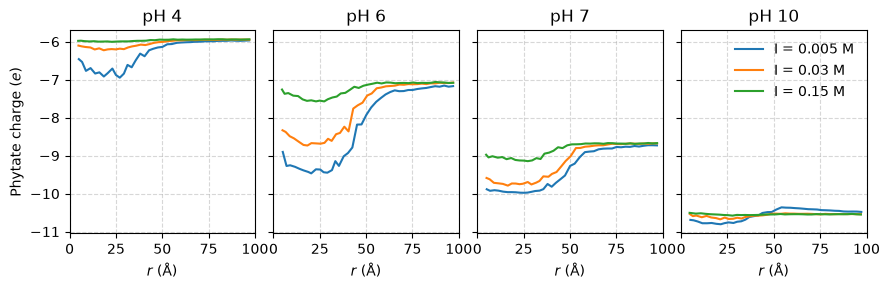

In [6]:
species = "charge_phytate"  # or "charge_peptide"

fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)


def plot_charge(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["charge"] is None or ionic == 1000:
            continue
        charge = row["charge"]
        ax.plot(charge.r, charge[species], label=f"I = {ionic:g} M")
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")


plot_charge(4.0, ax[0])
plot_charge(6.0, ax[1])
plot_charge(7.0, ax[2])
plot_charge(10.0, ax[3])
ax[0].set_xlim(0, 100)
ax[0].set_ylabel(r"Phytate charge ($e$)")
ax[3].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)

## Phytate alignment with the decorated wall

The PolymerShape analysis acts on the rigid, disk-like phytate (`Cp ≈ 0.94`). Its
gyration tensor is reported in the lab frame (z = wall normal), with trace
`Sxx + Syy + Szz = Rg²`. The orientation relative to the wall is the P₂ order
parameter of the mass distribution about z:

$$S_\text{wall} = \tfrac{1}{2}\left(3\,S_{zz}/R_g^2 - 1\right),\qquad R_g^2 = S_{xx}+S_{yy}+S_{zz}$$

- `S_wall = 0` — isotropic (no preferred orientation)
- `S_wall < 0` (down to −½) — disk lying **face-on** (plane parallel to the wall)
- `S_wall > 0` (up to +1) — disk **edge-on** (elongated along the wall normal)

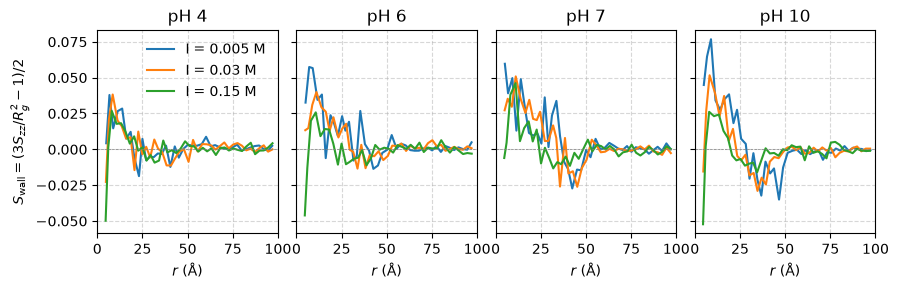

In [7]:
def wall_alignment(shape):
    """P2 order parameter of the phytate gyration tensor about the wall normal z."""
    rg2 = shape.Sxx + shape.Syy + shape.Szz
    return (3 * shape.Szz / rg2 - 1) / 2


def plot_alignment(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["shape"] is None or ionic == 1000:
            continue
        shape = row["shape"]
        ax.plot(shape.r, wall_alignment(shape), label=f"I = {ionic:g} M")
    ax.axhline(0, color="gray", ls="--", lw=0.5)
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")


fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)

for i, pH in enumerate([4, 6, 7, 10]):
    plot_alignment(pH, ax[i])

ax[0].set_xlim(0, 100)
ax[0].set_ylabel(r"$S_\mathrm{wall} = (3 S_{zz}/R_g^2 - 1)/2$")
ax[0].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)

## Effective electric potential due to the peptide brush (through implicit salt medium)

This is the effective electric potential felt by phytase at a given wall separation. Together with the phytate charge, this connects directly with the PMF plot.


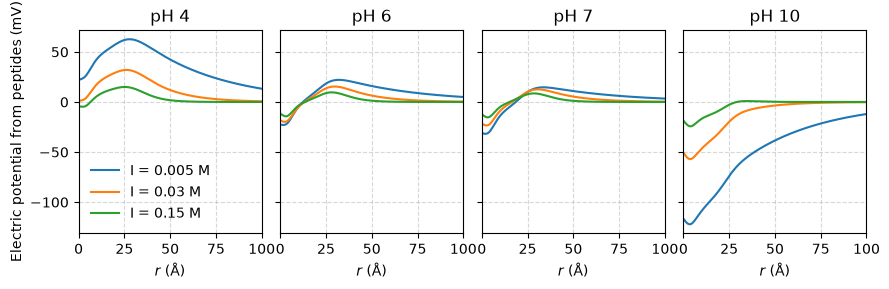

In [8]:
def plot_potential_peptide(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["potential_peptide"] is None or ionic == 1000:
            continue
        pot = row["potential_peptide"]
        ax.plot(pot.r, pot.potential_peptide_mV, label=f"I = {ionic:g} M")
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")


fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)

for i, pH in enumerate([4, 6, 7, 10]):
    plot_potential_peptide(pH, ax[i])

ax[0].set_xlim(0, 100)
ax[0].set_ylabel(r"Electric potential from peptides (mV)")
ax[0].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)

## Estimated ζ-potential (shear plane at the fixed-charge edge)

The ζ-potential is the electrostatic potential at the hydrodynamic shear plane. Taking that plane at the outer edge of the fixed brush charge — the largest r where the sampled peptide charge density σ(z) is still appreciable (≈40 Å) — the estimated ζ = φ(r_shear) falls monotonically from ≈+4 mV at pH 4 to ≈0 at pH 10, reproducing the sign and pH-trend of the measured ζ-potential (OB isoelectric point ≈ 6). Only the sign and trend are meaningful: the magnitude depends on the shear-plane choice — φ is several-fold larger read inside the brush — and on the planar, single-peptide model.

  pH  r_shear   zeta_mV
 4.0    42.75  3.847431
 6.0    40.75  3.365083
 7.0    40.25  3.050714
10.0    36.25 -0.067474


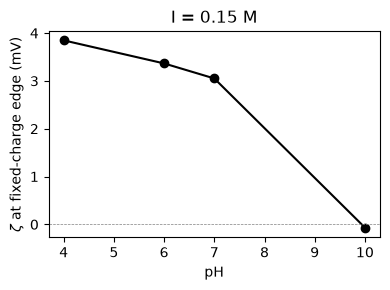

In [9]:
zeta = pd.read_csv("zeta.csv")
zeta_015 = zeta[zeta.ionic_strength == 0.15].sort_values("pH")
print(zeta_015[["pH", "r_shear", "zeta_mV"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(zeta_015.pH, zeta_015.zeta_mV, "o-", color="k")
ax.axhline(0, color="gray", ls="--", lw=0.5)
ax.set_xlabel("pH")
ax.set_ylabel(r"$\zeta$ at fixed-charge edge (mV)")
ax.set_title("I = 0.15 M")
fig.tight_layout()

## Free phytate diffusion (hydrodynamic estimate)

Rough tumbling/translation of *free* phytate from RDKit conformers + PyGRPY bead hydrodynamics (stick BC, water 25 °C) — `nmr/rotational_diffusion.py` → `nmr/diffusion.csv`. For each protonation state we generated 20 conformers (ETKDGv3 + MMFF); the inositol ring sampled both chair and twist/boat puckers, yet the hydrodynamic size barely varied (D_iso spread ≈ 4–5 %, R_g = 4.03 ± 0.05 Å), so a single ensemble mean is representative. Across protonation states (neutral → IP6¹²⁻):

- **τ_r ≈ 140–165 ps** (rotational correlation time), slowest when fully deprotonated.
- **D_rot ≈ 1.0–1.2 × 10⁹ rad²/s**, near-isotropic (D_max/D_min ≈ 1.2); **D_trans ≈ 4.4–4.7 × 10⁻¹⁰ m²/s**, Stokes radius **a_H ≈ 5.2–5.6 Å**, R_g ≈ 3.8–4.0 Å.

The difference between protonation states is purely **geometric**: deprotonation removes the peripheral hydrogen beads and reshapes the phosphate arms, altering the bare hydrodynamic shape. No electrostatic or ionic-atmosphere friction enters, so the net charge exerts no direct effect. With stick boundary conditions (slip could cut τ_r by up to ≈3×), these remain order-of-magnitude estimates (τ_r ≈ 10² ps). The tumbling time (≈10⁻¹⁰ s) is far faster than phytate diffusion across the brush PMF, so its orientation is effectively equilibrated along the reaction coordinate.

## Position-dependent rotational mobility (MC)

The MC `RotateMolecule` moves report a per-attempt mean-square angular displacement, pooled over the phytate protonation states in `extract_data.py`. Its ratio to the bulk (large-r) value is a rough, *comparative* rotational-diffusion profile

$$D(r)/D_0 \approx \langle\Delta\theta^2\rangle(r)\;/\;\langle\Delta\theta^2\rangle_\text{bulk},$$

showing how much the brush hinders phytate tumbling as it approaches the wall (bulk normalization = mean of the three outermost windows).

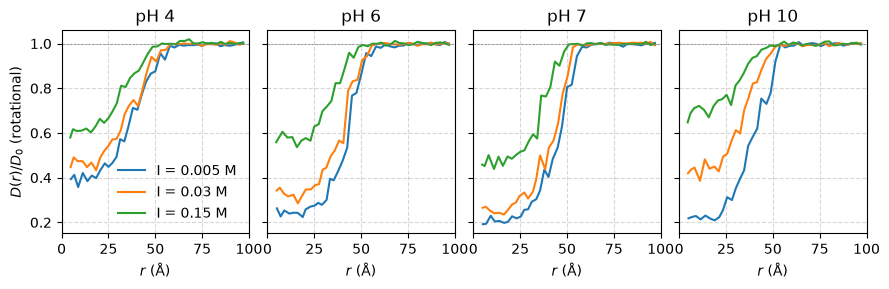

In [10]:
def plot_rotational_mobility(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["rot_msd"] is None or ionic == 1000:
            continue
        msd = row["rot_msd"]
        d0 = msd.msd_rot.iloc[-3:].mean()  # bulk = mean of the three outermost windows
        ax.plot(msd.r, msd.msd_rot / d0, label=f"I = {ionic:g} M")
    ax.axhline(1, color="gray", ls="--", lw=0.5)
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")


fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)

for i, pH in enumerate([4, 6, 7, 10]):
    plot_rotational_mobility(pH, ax[i])

ax[0].set_xlim(0, 100)
ax[0].set_ylabel(r"$D(r)/D_0$ (rotational)")
ax[0].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)

## Composite figure (manuscript)

Summary at fixed ionic strength (I = 0.15 M), one curve per pH: (A) PMF, (B) rotational mobility D(r)/D₀, (C) peptide-brush potential, (D) phytate charge.

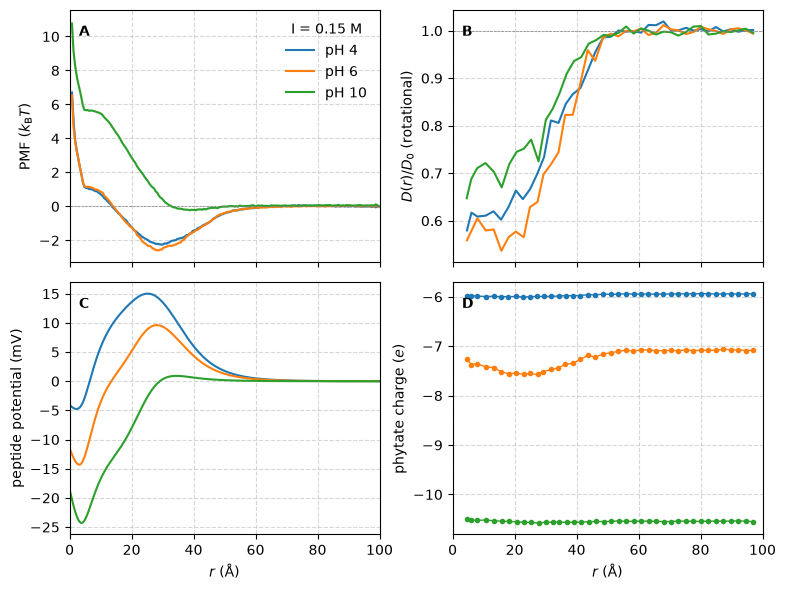

In [11]:
ionic = 0.15
phs = [4.0, 6.0, 10.0]
pH_color = {4.0: "C0", 6.0: "C1", 10.0: "C2"}  # blue / orange / green, matching the manuscript

fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True)
(axA, axB), (axC, axD) = axes

for pH in phs:
    row = data.loc[(ionic, pH)]
    c = pH_color[pH]

    pmf = row["pmf"]  # A: potential of mean force
    axA.fill_between(
        pmf.r, pmf.pmf_kT - pmf.stderr_kT, pmf.pmf_kT + pmf.stderr_kT, color=c, alpha=0.15
    )
    axA.plot(pmf.r, pmf.pmf_kT, color=c, label=f"pH {pH:g}")

    msd = row["rot_msd"]  # B: rotational mobility relative to bulk
    axB.plot(msd.r, msd.msd_rot / msd.msd_rot.iloc[-3:].mean(), color=c)

    pot = row["potential_peptide"]  # C: peptide-brush potential
    axC.plot(pot.r, pot.potential_peptide_mV, color=c)

    charge = row["charge"]  # D: phytate charge
    axD.plot(charge.r, charge.charge_phytate, color=c, marker="o", ms=3, lw=1)

axA.axhline(0, color="gray", ls="--", lw=0.5)
axA.set_ylabel(r"PMF ($k_\mathrm{B}T$)")
axB.axhline(1, color="gray", ls="--", lw=0.5)
axB.set_ylabel(r"$D(r)/D_0$ (rotational)")
axC.set_ylabel("peptide potential (mV)")
axD.set_ylabel(r"phytate charge ($e$)")
axC.set_xlabel(r"$r$ (Å)")
axD.set_xlabel(r"$r$ (Å)")

for ax, letter in zip(axes.flat, "ABCD"):
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.text(0.03, 0.94, letter, transform=ax.transAxes, fontweight="bold", va="top")

axA.legend(frameon=False, title=f"I = {ionic:g} M")
fig.tight_layout(w_pad=0)
fig.savefig("composite.png", dpi=200)

### Draft discussion text (for manuscript)

Monte Carlo simulations of phytate approaching a coarse-grained model of the oleosin N-terminal brush place the colloidal, thermodynamic, and spectroscopic observations on a common molecular mechanism (Figure X). At physiological ionic strength (0.15 M), the potential of mean force showed an attractive well at pH 4.0 and 6.0 — 2.3 and 2.6 $k_\mathrm{B}T$ deep, about 30 Å from the grafting surface — that vanished at pH 10.0 (0.2 $k_\mathrm{B}T$; Figure XA). This ordering, comparable attraction at acidic and near-isoelectric pH and none under alkaline conditions, follows the pH-dependence of binding measured by ITC and ζ-potential. The well deepened as the salt concentration was lowered (Figure SX), confirming its electrostatic origin and mirroring the double-layer screening that governs OB behaviour at pH 10.0.

The bound phytate behaved as a rigid, highly charged anion. Its net charge differed by less than 0.2 e between bulk and contact at every pH (Figure XD). Phytate therefore presents a fixed phosphate charge to the brush with only minor charge regulating upon approach — −6.0 e at pH 4.0, −7.1 e at pH 6.0, and −10.5 e at pH 10.0. The brush generated an electrostatic potential that deepened from −4 to −19 mV as pH rose from 4.0 to 10.0 (Figure XC), tracking the deprotonation of the oleosin residues that also shifts the OB surface charge toward negative values. These panels point to electrostatic attraction between the fixed phytate charge and the cationic oleosin domains, consistent with the enthalpy-driven binding resolved by ITC at pH 4.0.

The simulations also reproduced the dynamic signature seen by ³¹P MAS NMR. Phytate rotational mobility fell to about 0.6 of its bulk value at the interface and recovered with distance (Figure XB), so binding slows phytate tumbling without arresting it. This gradual, partial slowdown matches both the higher rotating-frame relaxation (ΔR) at pH 4.0 and 6.0 and the retained liquid-like mobility — the absent cross-polarization signal — at every pH. A bead-hydrodynamic estimate placed the free-phytate rotational correlation time near 0.1 ns, the fast-tumbling limit against which this hindrance is measured. Association with the slowly tumbling OB surface therefore lengthens the effective correlation time of phytate phosphorus while leaving its local motion liquid-like.

## gvdW adsorption isotherm → NMR bound fraction

Computes the numbers used in the Results section (`latex/methodology.tex`),
following Nordholm et al. (2018). The chain is:

- **$K_\text{H}$** (Eq. 4) — Henry adsorption constant from the PMF,
  $\int(e^{-w/k_BT}-1)\,dr$.
- **$\hat a_2$** (Eq. 6) — screened-Coulomb lateral coefficient from the
  simulated phytate charge $z(\text{pH})$ and the Debye length.
- **$\Gamma$** (Eq. 5) — the *implicit* 2D isotherm, solved
  **self-consistently by damped fixed-point iteration** ($\theta$ on both sides).
- **$f_\text{bound}=\Gamma a/n_B$** → two-site relaxation (Eq. 2).

At $I=0.15$ M the charge-dependent lateral repulsion ($\hat a_2\propto z^2$)
suppresses the more-charged pH-6 layer, flipping the bare-Henry ordering to
$f_\text{bound}(\text{pH 4}) > f_\text{bound}(\text{pH 6})$, as the NMR requires.

In [12]:
# --- gvdW adsorption: PMF -> bound fraction -> 31P relaxation (Results section) ---
KB, NA = 1.380649e-23, 6.02214076e23  # J/K, 1/mol
LB = 7.1528  # Bjerrum length in water, 298.15 K [A]
IONIC, PA_mM = 0.15, 7.6  # physiological salt [M], phytate [mM]
NMR = {4.0: (162, 559), 6.0: (130, 430), 10.0: (5.1, 52)}  # DeltaR (free, OB50%) [1/s]


def debye_length(ionic_M):
    """Debye length [A], 1:1 electrolyte in water at 298 K."""
    return 1.0 / np.sqrt(8 * np.pi * LB * ionic_M * NA / 1e27)


def henry_constant(pmf):
    """Eq (4): K_H = int (e^{-w/kT} - 1) dr [A]; w = bulk-referenced PMF."""
    return np.trapezoid(np.exp(-pmf.pmf_kT.values) - 1.0, pmf.r.values)


def phytate_valence(charge):
    """|z| from the bulk (large-r) phytate charge."""
    return abs(charge.charge_phytate.iloc[-3:].mean())


def alpha_lateral(z, ionic_M, d):
    """Eq (6): alpha = 2 a2/(kT d^2), a2/kT = -(pi z^2 lB/kappa) e^{-kappa d}."""
    kappa = 1.0 / debye_length(ionic_M)
    a2 = -(np.pi * z**2 * LB / kappa) * np.exp(-kappa * d)  # a2/kT [A^2]
    return 2.0 * a2 / d**2


def solve_coverage(phi0, alpha, tol=1e-12, itmax=1000):
    """Eq (5), coverage form, solved self-consistently (theta on both sides):
        theta = phi0 (1-theta) exp(alpha theta - theta/(1-theta)),  phi0 = K_H n_B d^2.
    Damped fixed-point iteration keeps theta in [0, 1)."""
    if phi0 <= 0:
        return 0.0
    theta = 0.0
    for _ in range(itmax):
        t = min(max(theta, 0.0), 0.999)
        new = min(phi0 * (1 - t) * np.exp(alpha * t - t / (1 - t)), 0.999)
        if abs(new - theta) < tol:
            return new
        theta += 0.5 * (new - theta)  # damping
    return theta


# phytate excluded diameter d ~ 2 a_H from PyGRPY; bulk phytate number density
d_A = 2 * pd.read_csv("../nmr/diffusion.csv").a_H_A.mean()
n_B = PA_mM * 1e-3 * NA / 1e27  # [1/A^3]
specific_area = lambda phi_ob, d43_um: 6.0 * phi_ob / (d43_um * 1e4)  # a = 6 phi / d43 [1/A]
a_OB = specific_area(0.50, 3.0)  # 50% OB, d43 = 3 um


def bound_fraction(K_H, alpha):
    """f_bound = Gamma a / n_B from the solved coverage; -> a K_H as theta -> 0."""
    theta = solve_coverage(K_H * n_B * d_A**2, alpha)
    return (theta / d_A**2) * a_OB / n_B, theta


rows = []
for pH in (4.0, 6.0, 7.0, 10.0):
    row = data.loc[(IONIC, pH)]
    K_H = henry_constant(row["pmf"])
    z = phytate_valence(row["charge"])
    alpha = alpha_lateral(z, IONIC, d_A)
    f_gvdw, theta = bound_fraction(K_H, alpha)
    rows.append(
        dict(
            pH=pH,
            z=-z,
            K_H_A=K_H,
            alpha=alpha,
            theta=theta,
            f_Henry=a_OB * K_H if K_H > 0 else 0.0,
            f_gvdW=f_gvdw,
        )
    )
gvdw = pd.DataFrame(rows).set_index("pH")
print(f"phytate disk d = {d_A:.1f} A,  n_B(7.6 mM) = {n_B:.2e} /A^3,  a(50% OB) = {a_OB:.2e} /A\n")
print(gvdw.to_string(float_format=lambda x: f"{x:.4g}"))

# two-site check (Eq 2): bound fraction the NMR requires vs. the gvdW prediction
print("\ntwo-site fast exchange, DeltaR_bound = 3e4 1/s:")
for pH in (4.0, 6.0, 10.0):
    free, obs = NMR[pH]
    f_req = (obs - free) / (3e4 - free)
    print(
        f"  pH {pH:g}: DeltaR {free}->{obs} 1/s   f_req={f_req:6.2%}   f_gvdW={gvdw.loc[pH, 'f_gvdW']:6.2%}"
    )

print("\npH4-vs-pH6 ordering (the discriminator):")
for tag in ("f_Henry", "f_gvdW"):
    order = "pH4 > pH6" if gvdw.loc[4.0, tag] > gvdw.loc[6.0, tag] else "pH6 > pH4"
    print(f"  {tag:8s}: {gvdw.loc[4.0, tag]:.2%} vs {gvdw.loc[6.0, tag]:.2%}  ->  {order}")

phytate disk d = 10.6 A,  n_B(7.6 mM) = 4.58e-06 /A^3,  a(50% OB) = 1.00e-04 /A

          z  K_H_A  alpha   theta  f_Henry   f_gvdW
pH                                                 
4.0  -5.941  132.8  -28.5 0.02862  0.01328 0.005542
6.0  -7.081  170.3 -40.48 0.02741  0.01703 0.005309
7.0  -8.671  220.2 -60.71 0.02448  0.02202  0.00474
10.0 -10.54 -26.84 -89.73       0        0        0

two-site fast exchange, DeltaR_bound = 3e4 1/s:
  pH 4: DeltaR 162->559 1/s   f_req= 1.33%   f_gvdW= 0.55%
  pH 6: DeltaR 130->430 1/s   f_req= 1.00%   f_gvdW= 0.53%
  pH 10: DeltaR 5.1->52 1/s   f_req= 0.16%   f_gvdW= 0.00%

pH4-vs-pH6 ordering (the discriminator):
  f_Henry : 1.33% vs 1.70%  ->  pH6 > pH4
  f_gvdW  : 0.55% vs 0.53%  ->  pH4 > pH6


## Analytical Gouy--Chapman gvdW binding model (ITC)

$K_\text{H}(\sigma_s, I)$ and $\hat a_2(\sigma_s, I)$ both derive from one surface
potential (Grahame + Gouy--Chapman) — self-consistent, one physical parameter. We fit
the **real** pH-4 thermogram (rep3 = `Official_3`, the run the manuscript reports;
loaded from the raw NanoAnalyze `.xls` by `itc/itc_data.py`). The independent one-site
fit reproduces NanoAnalyze's $K_a$, $n$, $\Delta H$ — validating the pipeline. The gvdW
model fits the same per-injection heats about as well (RMS $\approx$ 6–7 µJ), fitting
**either** the peptide charge $\sigma_s$ (at fixed buffer salt) **or** the ionic
strength $I$ (at fixed brush charge), returning values consistent with the simulated
brush ($\sigma_s\approx1.35\times10^{-3}\,e$/\AA$^2$) and the 3 mM buffer; the analytic
$K_\text{H}$ also matches the MC value. Loaders and fits in `itc/`.

In [13]:
# --- analytical Gouy-Chapman gvdW model + real-data ITC fits (itc/) ---
from scipy.optimize import brentq
import sys

sys.path.insert(0, "../itc")  # analytic model + ITC data/fits live in ../itc
import gc_gvdw as gc  # kappa, Grahame y0, GC profile, K_H_gc, alpha_gc
import itc_data
import itc_fit

I, z = 0.005, gc.Z_PA  # pH-4 buffer, phytate valence
print(f"pH 4, I = {I * 1e3:.0f} mM, z = {z}\n")
print(f"{'sigma_s(e/A^2)':>14} {'psi0(mV)':>9} {'K_H(A)':>11} {'alpha':>7}")
for s in (5e-4, 1e-3, 1.5e-3, 2e-3, 3e-3):
    y0 = gc.y0_grahame(s, I)
    print(f"{s:>14.1e} {y0 * gc.KT_MV:>8.0f}m {gc.K_H_gc(s, -z, I):>11.2e} {gc.alpha_gc(s, z, I):>7.0f}")

s_val = brentq(lambda s: np.log(gc.K_H_gc(s, -z, I)) - np.log(4.46e8), 1e-4, 5e-3)
print(f"\nvalidation vs MC K_H(5 mM) = 4.46e8 A:  sigma_s = {s_val:.2e} e/A^2  (brush {gc.SIGMA_BRUSH:.2e})")

# real pH-4 thermogram (Official_3 = the run the manuscript reports)
t = itc_data.load(4.0)
Ka, dH, n, rms = itc_fit.fit_onesite(t)
print(f"\none-site on real heats ({t.source}, [oleosin]={t.mt0 * 1e6:.0f} uM):")
print(f"  mine       : Ka={Ka:.2e}/M  n={n:.3f}  dH={dH:.1f} kJ/mol  (RMS {rms:.1f} uJ)")
f = t.na_fit
print(f"  NanoAnalyze: Ka={f['Ka']:.2e}/M  n={f['n']:.3f}  dH={f['dH']:.1f} kJ/mol")

print("\ngvdW fits of the same thermogram:")
I_eff, dH1, cap1, r1 = itc_fit.fit_gvdw(t, "fitI", gc.SIGMA_BRUSH)
print(f"  fix sigma_s = brush   -> I_eff   = {I_eff * 1e3:5.1f} mM     (cap {cap1:.1f}, dH {dH1:.1f}, RMS {r1:.1f} uJ)")
s_eff, dH2, cap2, r2 = itc_fit.fit_gvdw(t, "fitS", gc.I_BUFFER)
print(f"  fix I = buffer (5 mM) -> sigma_s = {s_eff:.2e} e/A^2 (cap {cap2:.1f}, dH {dH2:.1f}, RMS {r2:.1f} uJ)")


pH 4, I = 5 mM, z = 5.94

sigma_s(e/A^2)  psi0(mV)      K_H(A)   alpha
       5.0e-04       44m    3.73e+04    -236
       1.0e-03       73m    4.26e+06    -102
       1.5e-03       92m    8.59e+07     -51
       2.0e-03      106m    6.74e+08     -28
       3.0e-03      126m    9.69e+09     -10

validation vs MC K_H(5 mM) = 4.46e8 A:  sigma_s = 1.89e-03 e/A^2  (brush 1.35e-03)

one-site on real heats (pH4_rep3.xls, [oleosin]=48 uM):
  mine       : Ka=2.55e+05/M  n=0.380  dH=-47.4 kJ/mol  (RMS 5.9 uJ)
  NanoAnalyze: Ka=1.87e+05/M  n=0.322  dH=-56.4 kJ/mol

gvdW fits of the same thermogram:
  fix sigma_s = brush   -> I_eff   =   7.1 mM     (cap 5.5, dH -37.6, RMS 6.6 uJ)


  fix I = buffer (5 mM) -> sigma_s = 9.71e-04 e/A^2 (cap 9.6, dH -37.6, RMS 6.6 uJ)


## NMR pH-series from the local (dipolar) peptide potential

At $I=0.15$ M the near-isoelectric binding is a **dipole** effect: the oleosin arm
carries its cationic N-terminus at the outer binding edge and its anionic anchor at
the wall, so $\varphi_\text{pep}(r)$ is *positive at the binding site* (+8 to +15 mV
across pH 4--7) even when the net charge is ~0. Feeding this local potential — not the
net-charge/$\zeta$ monopole — into the mean-charge adsorption integral
$K_\text{H}=\int(e^{-Q e\varphi_\text{pep}/k_BT}-1)\,dr$ recovers binding at pH 4/6/7
and reproduces the PMF Henry constants at pH 6/7, while pH 10 stays repulsive. Phytate
charge regulation adds only a few % at 150 mM and is omitted for simplicity.

In [14]:
# --- NMR pH-series: mean phytate charge in the local dipolar peptide potential (I=0.15 M) ---
kT_mV = 25.693  # kT/e [mV] at 298.15 K
print(f"{'pH':>4} {'Q':>6} {'phi_patch(mV)':>13} {'K_H(A)':>8}")
for pH in (4.0, 6.0, 7.0, 10.0):
    row = data.loc[(0.15, pH)]
    Q = row["charge"].charge_phytate.iloc[-3:].mean()  # bulk phytate charge (window39)
    p = row["potential_peptide"]
    m = (p.r >= 10) & (p.r <= 60)  # brush binding region (exclude core)
    r, y = p.r[m].values, p.potential_peptide_mV[m].values / kT_mV
    K_H = np.trapezoid(np.exp(-Q * y) - 1, r)  # mean-charge adsorption integral
    phi_patch = p[(p.r > 20) & (p.r < 40)].potential_peptide_mV.max()  # + N-terminal patch
    print(f"{pH:>4} {Q:>6.1f} {phi_patch:>+13.1f} {K_H:>8.1f}")
# pH 4/6/7 bind (positive outer patch), pH 10 repulsive; K_H(pH6,7) match the PMF (170, 220 A).

  pH      Q phi_patch(mV)   K_H(A)
 4.0   -5.9         +15.0    507.2
 6.0   -7.1          +9.6    179.8
 7.0   -8.7          +8.6    216.6
10.0  -10.5          +0.9     -9.6


## Composite at low ionic strength (I = 0.005 M) with measured ζ

The same panels at the low-salt limit — matching the diluted ζ-potential measurement, and the regime where the electrostatic binding is strongest. Panel C overlays the measured bare-OB ζ (filled squares, ± SD, Fig 6B) against the simulated ζ at the fixed-charge edge (open circles).

I = 5 mM is the realistic lower bound for the measurements: counterions of the charged oil-body surface and of phytate, together with residual ionic species, sustain millimolar screening even after dilution, and lower ionic strengths are not reliably accessible experimentally. The remaining caveats are the shear-plane choice (φ is several-fold larger read inside the brush) and the planar, single-peptide model.

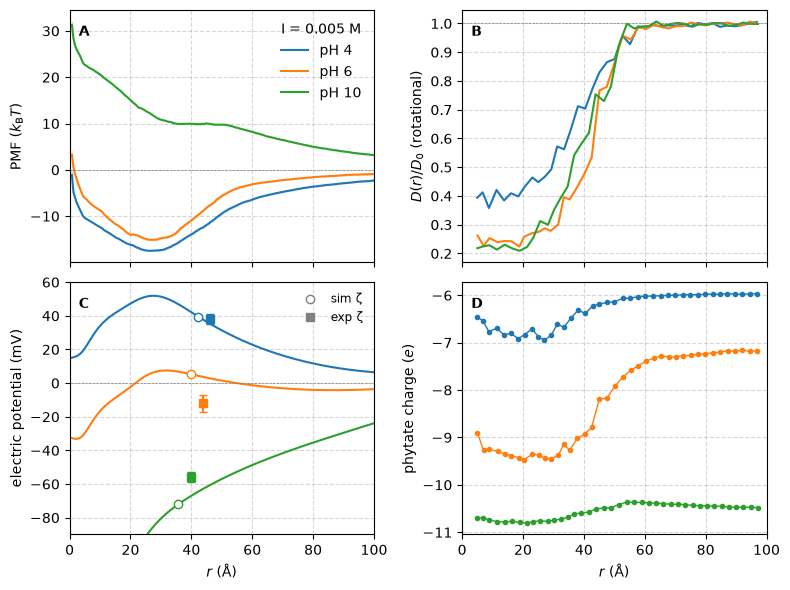

In [15]:
from matplotlib.lines import Line2D

ionic = 0.005
phs = [4.0, 6.0, 10.0]
pH_color = {4.0: "C0", 6.0: "C1", 10.0: "C2"}  # blue / orange / green, matching the manuscript

# Measured bare-OB ζ (no added PA, diluted -> low salt; Fig 6B)
exp = pd.read_csv("experimental_zeta.csv")
exp_zeta = {r.pH: (r.zeta_mV, r.zeta_sd_mV) for r in exp[exp.PA_mM == 0].itertuples()}

zeta = pd.read_csv("zeta.csv")

fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True)
(axA, axB), (axC, axD) = axes

for pH in phs:
    row = data.loc[(ionic, pH)]
    c = pH_color[pH]

    pmf = row["pmf"]  # A: potential of mean force
    axA.fill_between(
        pmf.r, pmf.pmf_kT - pmf.stderr_kT, pmf.pmf_kT + pmf.stderr_kT, color=c, alpha=0.15
    )
    axA.plot(pmf.r, pmf.pmf_kT, color=c, label=f"pH {pH:g}")

    msd = row["rot_msd"]  # B: rotational mobility relative to bulk
    axB.plot(msd.r, msd.msd_rot / msd.msd_rot.iloc[-3:].mean(), color=c)

    pot = row["potential_all"]  # C: total potential; markers compare ζ at the shear plane
    axC.plot(pot.r, pot.potential_all_mV, color=c)
    zc = zeta[(zeta.ionic_strength == ionic) & (zeta.pH == pH)].iloc[0]
    axC.plot(zc.r_shear, zc.zeta_mV, "o", mfc="white", mec=c, zorder=5)  # simulated ζ
    mean, sd = exp_zeta[pH]
    axC.errorbar(zc.r_shear + 4, mean, yerr=sd, fmt="s", color=c, capsize=3, zorder=5)  # measured ζ

    charge = row["charge"]  # D: phytate charge
    axD.plot(charge.r, charge.charge_phytate, color=c, marker="o", ms=3, lw=1)

axA.axhline(0, color="gray", ls="--", lw=0.5)
axA.set_ylabel(r"PMF ($k_\mathrm{B}T$)")
axB.axhline(1, color="gray", ls="--", lw=0.5)
axB.set_ylabel(r"$D(r)/D_0$ (rotational)")
axC.axhline(0, color="gray", ls="--", lw=0.5)
axC.set_ylabel("electric potential (mV)")
axC.set_ylim(-90, 60)
axD.set_ylabel(r"phytate charge ($e$)")
axC.set_xlabel(r"$r$ (Å)")
axD.set_xlabel(r"$r$ (Å)")

for ax, letter in zip(axes.flat, "ABCD"):
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.text(0.03, 0.94, letter, transform=ax.transAxes, fontweight="bold", va="top")

axA.legend(frameon=False, title=f"I = {ionic:g} M")
axC.legend(
    handles=[
        Line2D([], [], marker="o", mfc="white", mec="gray", ls="", label="sim ζ"),
        Line2D([], [], marker="s", color="gray", ls="", label="exp ζ"),
    ],
    frameon=False,
    fontsize="small",
    loc="upper right",
)
fig.tight_layout()
fig.savefig("composite_lowsalt.png", dpi=200)